# 01 · Formativa 1 — Análisis exploratorio e inferencial

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello · Grupo 8

**Dataset:** *Predict Students' Dropout and Academic Success* (UCI, 2021).

Este cuaderno reproduce todos los resultados del informe de la Formativa 1 y genera sus cinco figuras en la
carpeta `figuras/`. Antes debe haberse ejecutado una vez `00_generacion_faltantes.ipynb`. Orden:

0. Carga de datos y definición de la variable objetivo
1. Estadística descriptiva (ID1.2)
2. Estimación puntual e intervalos de confianza (ID1.3)
3. Pruebas de hipótesis (ID1.4)
4. Resumen de resultados

## 0. Carga de datos y definición de la variable objetivo

La variable `Target` tiene tres clases: *Graduate*, *Dropout* y *Enrolled*. El apunte de bases de datos
(sección 3.8) indica que hay que **seleccionar dos** y convertir el problema en binario. El equipo trabaja durante
todo el proyecto con:

- **1 = Dropout** (deserta)
- **0 = Graduate** (se gradúa)

Se excluyen los estudiantes *Enrolled* porque siguen matriculados y su desenlace todavía no se conoce: podrían
desertar o graduarse más adelante.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import os

SEMILLA = 42
ALFA = 0.05
OBJETIVO = 'Deserta'                     # 1 = Dropout, 0 = Graduate
os.makedirs('../figuras', exist_ok=True)

df_completo = pd.read_csv('../data/processed/data_con_faltantes.csv')
print('Dataset con faltantes generados:', df_completo.shape)
print(df_completo['Target'].value_counts(), '\n')

df = df_completo[df_completo['Target'].isin(['Dropout', 'Graduate'])].copy()
df[OBJETIVO] = (df['Target'] == 'Dropout').astype(int)
n = len(df)
print(f'Estudiantes analizados (Dropout + Graduate): {n:,}')
print(f"Excluidos (Enrolled): {(df_completo['Target'] == 'Enrolled').sum():,}")

Dataset con faltantes generados: (4424, 38)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64 

Estudiantes analizados (Dropout + Graduate): 3,630
Excluidos (Enrolled): 794


### Estilo de las figuras
Azul para quienes se gradúan y naranja para quienes desertan, en todas las figuras.

In [2]:
AZUL    = '#2a78d6'   # Graduate / serie principal
NARANJA = '#eb6834'   # Dropout
GRIS    = '#52514e'
GRILLA  = '#e4e3df'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8c8b86', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRILLA, 'grid.linewidth': 0.8,
})

def coma(x, dec=1):
    # Formato chileno: coma decimal y punto de miles
    return f'{x:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

## 1. Estadística descriptiva (ID1.2)

### 1.1 Tipos de variables
pandas lee las 36 variables como números, pero muchas son categorías codificadas (por ejemplo, `Course` = 9500
es un código de carrera, no una cantidad). Se clasifican antes de calcular cualquier medida.

In [3]:
continuas = ['Admission grade', 'Previous qualification (grade)',
             'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
             'Unemployment rate', 'Inflation rate', 'GDP']
discretas = ['Age at enrollment'] + [c for c in df.columns if c.startswith('Curricular units') and '(grade)' not in c]
binarias  = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
             'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
ordinales = ['Application order']
nominales = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

clasificacion = pd.DataFrame(
    [(c, 'Cuantitativa continua') for c in continuas] + [(c, 'Cuantitativa discreta') for c in discretas] +
    [(c, 'Cualitativa binaria') for c in binarias] + [(c, 'Cualitativa ordinal') for c in ordinales] +
    [(c, 'Cualitativa nominal') for c in nominales], columns=['Variable', 'Tipo'])
print('Variables clasificadas:', len(clasificacion), '\n')
print(clasificacion['Tipo'].value_counts())
clasificacion

Variables clasificadas: 36 

Tipo
Cuantitativa discreta    11
Cualitativa nominal       9
Cualitativa binaria       8
Cuantitativa continua     7
Cualitativa ordinal       1
Name: count, dtype: int64


,Variable,Tipo
0,Admission grade,Cuantitativa continua
1,Previous qualification (grade),Cuantitativa continua
2,Curricular units 1st sem (grade),Cuantitativa continua
3,Curricular units 2nd sem (grade),Cuantitativa continua
4,Unemployment rate,Cuantitativa continua
5,Inflation rate,Cuantitativa continua
6,GDP,Cuantitativa continua
7,Age at enrollment,Cuantitativa discreta
8,Curricular units 1st sem (credited),Cuantitativa discreta
9,Curricular units 1st sem (enrolled),Cuantitativa discreta


### 1.2 Calidad de datos
Se revisan duplicados, faltantes (los generados en el paso 00) y una inconsistencia propia del dataset: la nota
del semestre vale 0 cuando el estudiante no aprobó ninguna unidad curricular. Ese 0 no es una nota real.

In [4]:
print(f"Filas duplicadas: {df.drop(columns='id_estudiante').duplicated().sum()}")
falt = df.isna().sum(); falt = falt[falt > 0]
print('Faltantes:'); print(pd.DataFrame({'n': falt, '%': (falt / n * 100).round(2)}), '\n')

for sem in ['1st', '2nd']:
    nota, aprob = f'Curricular units {sem} sem (grade)', f'Curricular units {sem} sem (approved)'
    print(f"{sem} sem: nota = 0 en {(df[nota] == 0).sum()} estudiantes; "
          f"coincide con 0 unidades aprobadas: {((df[nota] == 0) == (df[aprob] == 0)).all()}; "
          f"menor nota distinta de 0: {df.loc[df[nota] > 0, nota].min()}")

Filas duplicadas: 0
Faltantes:
                     n      %
Admission grade    453  12.48
Age at enrollment  426  11.74 

1st sem: nota = 0 en 647 estudiantes; coincide con 0 unidades aprobadas: True; menor nota distinta de 0: 9.8
2nd sem: nota = 0 en 802 estudiantes; coincide con 0 unidades aprobadas: True; menor nota distinta de 0: 10.0


In [5]:
# Las notas en 0 se tratan como 'sin nota' (no aprobó unidades) para las medidas de la nota
for sem in ['1st', '2nd']:
    col = f'Curricular units {sem} sem (grade)'
    df[col + ' sin ceros'] = df[col].where(df[col] > 0)

### 1.3 Medidas resumen de las variables cuantitativas (Tabla 2 del informe)

In [6]:
cuant = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
         'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
         'Curricular units 1st sem (grade) sin ceros', 'Curricular units 2nd sem (grade) sin ceros',
         'Unemployment rate']
desc = pd.DataFrame({
    'n': df[cuant].count(),
    'Media': df[cuant].mean(), 'Mediana': df[cuant].median(), 'Desv. est.': df[cuant].std(),
    'CV %': df[cuant].std() / df[cuant].mean() * 100,
    'RIC': df[cuant].quantile(0.75) - df[cuant].quantile(0.25),
    'Mínimo': df[cuant].min(), 'Máximo': df[cuant].max(), 'Asimetría': df[cuant].skew(),
})
desc.round(2)

,n,Media,Mediana,Desv. est.,CV %,RIC,Mínimo,Máximo,Asimetría
Age at enrollment,3204,23.47,20.00,7.82,33.30,6.00,17.0,70.00,2.01
Admission grade,3177,127.28,126.50,14.47,11.37,17.40,95.0,190.00,0.48
Previous qualification (grade),3630,132.92,133.10,13.24,9.96,15.00,95.0,190.00,0.29
Curricular units 1st sem (approved),3630,4.79,5.00,3.24,67.58,3.00,0.0,26.00,0.75
Curricular units 2nd sem (approved),3630,4.52,5.00,3.16,69.99,4.00,0.0,20.00,0.27
Curricular units 1st sem (grade) sin ceros,2983,12.82,12.75,1.35,10.55,1.88,9.8,18.88,0.30
Curricular units 2nd sem (grade) sin ceros,2828,12.88,12.83,1.38,10.69,1.91,10.0,18.57,0.28
Unemployment rate,3630,11.63,11.10,2.67,22.94,4.50,7.6,16.20,0.19


### 1.4 Frecuencias de las variables cualitativas (Tabla 3 del informe)

In [7]:
etiquetas = {'Gender': 'Hombre', 'Scholarship holder': 'Becado', 'Debtor': 'Deudor',
             'Tuition fees up to date': 'Matrícula al día', 'Displaced': 'Desplazado',
             'Daytime/evening attendance': 'Jornada diurna', 'International': 'Internacional',
             'Educational special needs': 'Necesidades educativas especiales'}
frec = pd.DataFrame({'Categoría (valor 1)': pd.Series(etiquetas),
                     'Frecuencia': df[binarias].sum(), '%': (df[binarias].mean() * 100).round(1)})
display(frec.sort_values('%', ascending=False))

estado = df['Marital status'].map({1: 'Soltero', 2: 'Casado', 3: 'Viudo', 4: 'Divorciado',
                                   5: 'Unión de hecho', 6: 'Separado legalmente'})
pd.DataFrame({'Frecuencia': estado.value_counts(), '%': (estado.value_counts(normalize=True) * 100).round(1)})

,Categoría (valor 1),Frecuencia,%
Daytime/evening attendance,Jornada diurna,3222,88.8
Tuition fees up to date,Matrícula al día,3144,86.6
Displaced,Desplazado,1993,54.9
Gender,Hombre,1249,34.4
Scholarship holder,Becado,969,26.7
Debtor,Deudor,413,11.4
International,Internacional,86,2.4
Educational special needs,Necesidades educativas especiales,40,1.1


,Frecuencia,%
Marital status,,
Soltero,3199,88.1
Casado,327,9.0
Divorciado,75,2.1
Unión de hecho,22,0.6
Separado legalmente,5,0.1
Viudo,2,0.1


### Figura 1 - Variable objetivo y datos faltantes

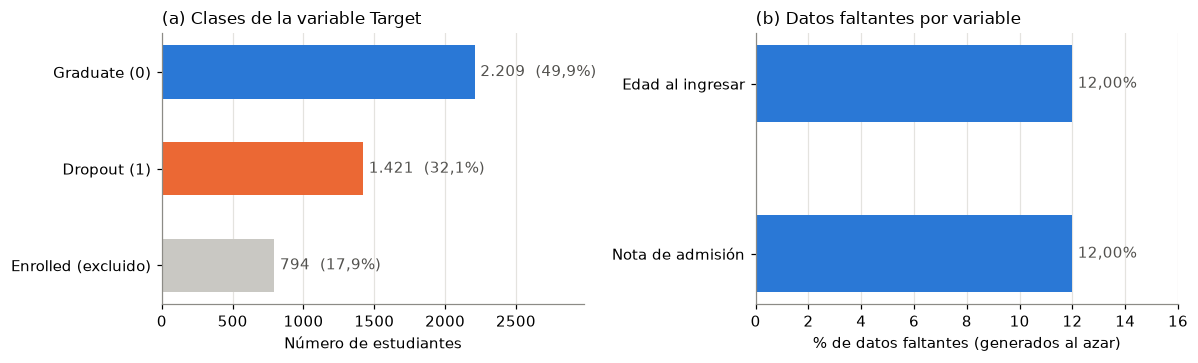

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))

conteo = df_completo['Target'].value_counts().reindex(['Graduate', 'Dropout', 'Enrolled'])
nombres = ['Graduate (0)', 'Dropout (1)', 'Enrolled (excluido)']
colores = [AZUL, NARANJA, '#c9c8c3']
ax[0].barh(nombres, conteo.values, color=colores, height=0.55)
ax[0].invert_yaxis()
for i, v in enumerate(conteo.values):
    ax[0].text(v + 40, i, f'{coma(v, 0)}  ({coma(v / conteo.sum() * 100)}%)', va='center', color=GRIS)
ax[0].set_xlim(0, conteo.max() * 1.35)
ax[0].set_xlabel('Número de estudiantes')
ax[0].set_title('(a) Clases de la variable Target')
ax[0].grid(axis='y', visible=False)

pct = (df_completo.isna().mean() * 100)
pct = pct[pct > 0].sort_values()
etq = {'Admission grade': 'Nota de admisión', 'Age at enrollment': 'Edad al ingresar'}
ax[1].barh([etq[c] for c in pct.index], pct.values, color=AZUL, height=0.45)
for i, v in enumerate(pct.values):
    ax[1].text(v + 0.2, i, f'{coma(v, 2)}%', va='center', color=GRIS)
ax[1].set_xlim(0, 16)
ax[1].set_xlabel('% de datos faltantes (generados al azar)')
ax[1].set_title('(b) Datos faltantes por variable')
ax[1].grid(axis='y', visible=False)

plt.tight_layout()
plt.savefig('../figuras/fig1_objetivo_faltantes.png')
plt.show()

### Figura 2 - Distribución de tres variables cuantitativas

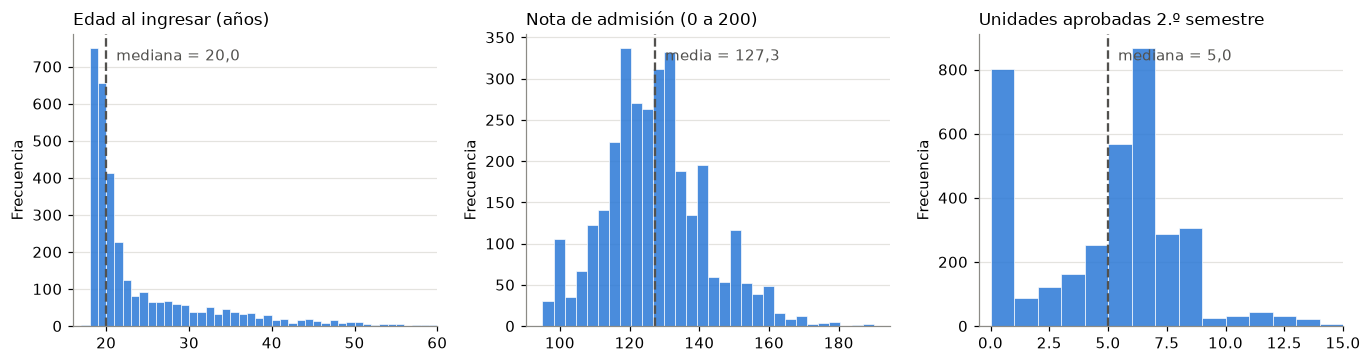

In [9]:
paneles = [('Age at enrollment', 'Edad al ingresar (años)', 'mediana', 1),
           ('Admission grade', 'Nota de admisión (0 a 200)', 'media', 2),
           ('Curricular units 2nd sem (approved)', 'Unidades aprobadas 2.º semestre', 'mediana', 1)]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
for ax, (col, titulo, nombre, bins_ancho) in zip(axes, paneles):
    x = df[col].dropna()
    ref = x.median() if nombre == 'mediana' else x.mean()
    bins = np.arange(x.min(), x.max() + bins_ancho, bins_ancho) if bins_ancho == 1 else 30
    ax.hist(x, bins=bins, color=AZUL, alpha=0.85, edgecolor='white', linewidth=0.5)
    ax.axvline(ref, color=GRIS, ls='--', lw=1.5)
    ax.text(ref, ax.get_ylim()[1] * 0.95, f'  {nombre} = {coma(ref)}', color=GRIS, va='top')
    ax.set_title(titulo); ax.set_ylabel('Frecuencia'); ax.grid(axis='x', visible=False)
axes[0].set_xlim(16, 60)
axes[2].set_xlim(-0.5, 15)

plt.tight_layout()
plt.savefig('../figuras/fig2_distribuciones.png')
plt.show()

### Figura 3 - Unidades aprobadas y edad según el desenlace (diagramas de caja)

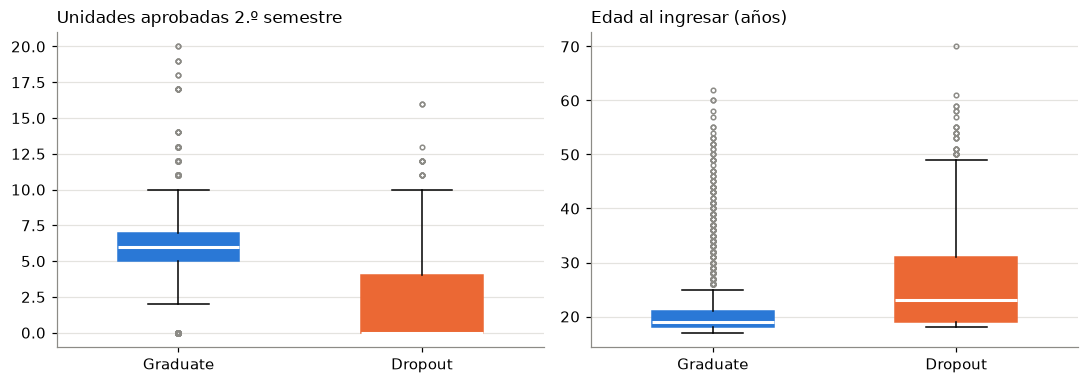

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (col, titulo) in zip(axes, [('Curricular units 2nd sem (approved)', 'Unidades aprobadas 2.º semestre'),
                                    ('Age at enrollment', 'Edad al ingresar (años)')]):
    grupos = [df.loc[df[OBJETIVO] == g, col].dropna() for g in (0, 1)]
    cajas = ax.boxplot(grupos, patch_artist=True, widths=0.5,
                       medianprops=dict(color='white', linewidth=2),
                       flierprops=dict(marker='o', markersize=3, markerfacecolor='none', markeredgecolor='#8c8b86'))
    for caja, color in zip(cajas['boxes'], [AZUL, NARANJA]):
        caja.set_facecolor(color); caja.set_edgecolor(color)
    ax.set_xticks([1, 2]); ax.set_xticklabels(['Graduate', 'Dropout'])
    ax.set_title(titulo); ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.savefig('../figuras/fig3_cajas_por_desenlace.png')
plt.show()

### Figura 4 - Matriz de correlaciones de Pearson

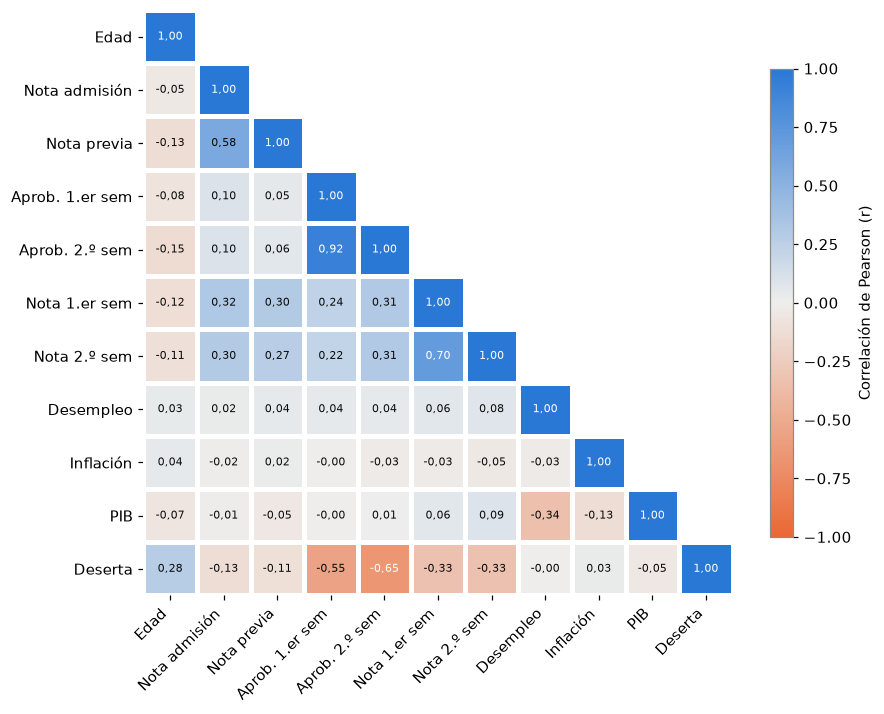

Curricular units 2nd sem (approved)          -0.654
Curricular units 1st sem (approved)          -0.555
Curricular units 2nd sem (grade) sin ceros   -0.333
Curricular units 1st sem (grade) sin ceros   -0.328
Admission grade                              -0.125
Previous qualification (grade)               -0.109
GDP                                          -0.050
Unemployment rate                            -0.004
Inflation rate                                0.030
Age at enrollment                             0.276
Name: Deserta, dtype: float64

In [11]:
cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
        'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)',
        'Curricular units 1st sem (grade) sin ceros', 'Curricular units 2nd sem (grade) sin ceros',
        'Unemployment rate', 'Inflation rate', 'GDP', OBJETIVO]
cortos = ['Edad', 'Nota admisión', 'Nota previa', 'Aprob. 1.er sem', 'Aprob. 2.º sem',
          'Nota 1.er sem', 'Nota 2.º sem', 'Desempleo', 'Inflación', 'PIB', 'Deserta']
corr = df[cols].corr()          # cada par usa los casos disponibles; las notas excluyen los ceros
k = len(corr)
oculto = np.triu(np.ones((k, k), dtype=bool), k=1)
mapa = LinearSegmentedColormap.from_list('divergente', [NARANJA, '#eeeeec', AZUL])

fig, ax = plt.subplots(figsize=(8.2, 6.6))
ax.grid(False)
im = ax.pcolormesh(np.ma.masked_array(corr.values, oculto), cmap=mapa, vmin=-1, vmax=1,
                   edgecolors='white', linewidth=2)
ax.invert_yaxis()
for i in range(k):
    for j in range(i + 1):
        v = corr.values[i, j]
        ax.text(j + 0.5, i + 0.5, coma(v, 2), ha='center', va='center', fontsize=7.5,
                color='white' if abs(v) > 0.6 else '#0b0b0b')
ax.set_xticks(np.arange(k) + 0.5); ax.set_xticklabels(cortos, rotation=45, ha='right')
ax.set_yticks(np.arange(k) + 0.5); ax.set_yticklabels(cortos)
for lado in ax.spines.values():
    lado.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='Correlación de Pearson (r)')
plt.tight_layout()
plt.savefig('../figuras/fig4_correlaciones.png')
plt.show()

corr[OBJETIVO].drop(OBJETIVO).sort_values().round(3)

### Figura 5 - Porcentaje de deserción según factores cualitativos, con IC al 95 %

,Factor,Grupo,n,% deserta,IC inf.,IC sup.
0,Matrícula al día,Sí,3144,30.7,29.0,32.3
1,Matrícula al día,No,486,94.0,91.9,96.1
2,Deudor,Sí,413,75.5,71.4,79.7
3,Deudor,No,3217,34.5,32.8,36.1
4,Becado,Sí,969,13.8,11.7,16.0
5,Becado,No,2661,48.4,46.5,50.3
6,Sexo,Hombre,1249,56.1,53.4,58.9
7,Sexo,Mujer,2381,30.2,28.4,32.1
8,Jornada,Diurna,3222,37.7,36.0,39.4
9,Jornada,Vespertina,408,50.7,45.9,55.6


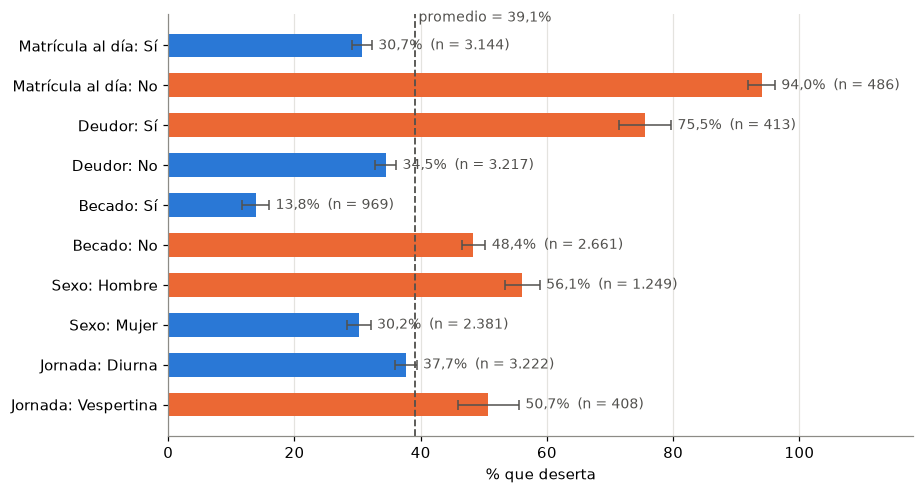

In [12]:
factores = [('Tuition fees up to date', 'Matrícula al día', {0: 'No', 1: 'Sí'}),
            ('Debtor', 'Deudor', {0: 'No', 1: 'Sí'}),
            ('Scholarship holder', 'Becado', {0: 'No', 1: 'Sí'}),
            ('Gender', 'Sexo', {0: 'Mujer', 1: 'Hombre'}),
            ('Daytime/evening attendance', 'Jornada', {0: 'Vespertina', 1: 'Diurna'})]
filas = []
for col, nombre, mapa_v in factores:
    for v in (1, 0):
        g = df.loc[df[col] == v, OBJETIVO]
        p = g.mean(); ee = np.sqrt(p * (1 - p) / len(g))
        filas.append({'Factor': nombre, 'Grupo': mapa_v[v], 'n': len(g),
                      '% deserta': p * 100, 'IC inf.': (p - 1.96 * ee) * 100, 'IC sup.': (p + 1.96 * ee) * 100})
tasas = pd.DataFrame(filas)
display(tasas.round(1))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(tasas))[::-1]
global_pct = df[OBJETIVO].mean() * 100
color = [NARANJA if r['% deserta'] > global_pct else AZUL for _, r in tasas.iterrows()]
ax.barh(y, tasas['% deserta'], color=color, height=0.6)
ax.errorbar(tasas['% deserta'], y, xerr=[tasas['% deserta'] - tasas['IC inf.'], tasas['IC sup.'] - tasas['% deserta']],
            fmt='none', ecolor=GRIS, capsize=3, lw=1)
for yi, (_, r) in zip(y, tasas.iterrows()):
    ax.text(r['IC sup.'] + 1, yi, f"{coma(r['% deserta'])}%  (n = {coma(r['n'], 0)})", va='center', color=GRIS, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([f"{r['Factor']}: {r['Grupo']}" for _, r in tasas.iterrows()])
ax.axvline(global_pct, color=GRIS, ls='--', lw=1.2)
ax.text(global_pct + 0.5, y.max() + 0.6, f'promedio = {coma(global_pct)}%', color=GRIS, fontsize=9)
ax.set_xlim(0, 118); ax.set_xlabel('% que deserta')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig('../figuras/fig5_desercion_por_factor.png')
plt.show()

## 2. Estimación puntual e intervalos de confianza (ID1.3)

- **Media:** $\bar{x} \pm t_{0.975,\,n-1}\cdot s/\sqrt{n}$ (desviación estándar poblacional desconocida).
- **Proporción:** $\hat{p} \pm z_{0.975}\cdot\sqrt{\hat{p}(1-\hat{p})/n}$.
- **Mediana:** *bootstrap* de percentiles con 5.000 remuestras (semilla 42), porque no tiene una fórmula sencilla de error estándar.

Las variables con faltantes usan los casos disponibles; por eso cada fila informa su propio *n*.

In [13]:
def ic_media(x, conf=0.95):
    x = pd.Series(x).dropna()
    m, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    t = stats.t.ppf(1 - (1 - conf) / 2, df=len(x) - 1)
    return m, m - t * ee, m + t * ee, len(x)

def ic_proporcion(x, conf=0.95):
    x = pd.Series(x).dropna()
    p = x.mean(); z = stats.norm.ppf(1 - (1 - conf) / 2); ee = np.sqrt(p * (1 - p) / len(x))
    return p, p - z * ee, p + z * ee, len(x)

parametros = [('Edad media al ingresar (años)', ic_media(df['Age at enrollment'])),
              ('Nota de admisión media', ic_media(df['Admission grade'])),
              ('Unidades aprobadas medias, 1.er semestre', ic_media(df['Curricular units 1st sem (approved)'])),
              ('Unidades aprobadas medias, 2.º semestre', ic_media(df['Curricular units 2nd sem (approved)'])),
              ('Proporción que deserta', ic_proporcion(df[OBJETIVO])),
              ('Proporción con beca', ic_proporcion(df['Scholarship holder']))]
tabla_ic = pd.DataFrame([{'Parámetro': p, 'Estimación': r[0], 'IC 95% inf.': r[1], 'IC 95% sup.': r[2], 'n': r[3]}
                         for p, r in parametros]).set_index('Parámetro')
tabla_ic.round(4)

,Estimación,IC 95% inf.,IC 95% sup.,n
Parámetro,,,,
Edad media al ingresar (años),23.4679,23.1971,23.7386,3204
Nota de admisión media,127.2849,126.7814,127.7883,3177
"Unidades aprobadas medias, 1.er semestre",4.7915,4.6861,4.8968,3630
"Unidades aprobadas medias, 2.º semestre",4.5185,4.4155,4.6214,3630
Proporción que deserta,0.3915,0.3756,0.4073,3630
Proporción con beca,0.2669,0.2526,0.2813,3630


In [14]:
# Bootstrap para la mediana de la nota de admisión
rng = np.random.default_rng(SEMILLA)
nota = df['Admission grade'].dropna().to_numpy()
medianas = np.array([np.median(rng.choice(nota, size=len(nota), replace=True)) for _ in range(5000)])
medias   = np.array([rng.choice(nota, size=len(nota), replace=True).mean() for _ in range(5000)])
print(f'Mediana de la nota de admisión: {np.median(nota):.2f}   (media {nota.mean():.2f})')
print(f'IC 95% bootstrap de la mediana: [{np.percentile(medianas, 2.5):.2f}; {np.percentile(medianas, 97.5):.2f}]')
print(f'IC 95% bootstrap de la media  : [{np.percentile(medias, 2.5):.2f}; {np.percentile(medias, 97.5):.2f}]')

Mediana de la nota de admisión: 126.50   (media 127.28)
IC 95% bootstrap de la mediana: [126.00; 127.00]
IC 95% bootstrap de la media  : [126.78; 127.80]


## 3. Pruebas de hipótesis (ID1.4)

Nivel de significancia $\alpha = 0{,}05$, el valor convencional: acepta un 5 % de riesgo de rechazar una
hipótesis nula verdadera. Como cada prueba usa más de 1.000 observaciones, valores *p* muy pequeños son
esperables; por eso cada resultado se acompaña de su tamaño del efecto.

### 3.1 Prueba *t* de Welch: unidades aprobadas en el 2.º semestre
$H_0:\ \mu_{\text{Dropout}} = \mu_{\text{Graduate}}$ vs. $H_1:\ \mu_{\text{Dropout}} \neq \mu_{\text{Graduate}}$.

In [15]:
def welch(col):
    a = df.loc[df[OBJETIVO] == 1, col].dropna()      # Dropout
    b = df.loc[df[OBJETIVO] == 0, col].dropna()      # Graduate
    lev_stat, lev_p = stats.levene(a, b)             # supuesto de igualdad de varianzas
    t, p = stats.ttest_ind(a, b, equal_var=False)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    d = (a.mean() - b.mean()) / sp
    ee = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    gl = ee**4 / ((a.var(ddof=1) / len(a))**2 / (len(a) - 1) + (b.var(ddof=1) / len(b))**2 / (len(b) - 1))
    dif = a.mean() - b.mean(); margen = stats.t.ppf(0.975, gl) * ee
    print(f"Dropout : media = {a.mean():.2f}  desv. = {a.std():.2f}  n = {len(a):,}")
    print(f"Graduate: media = {b.mean():.2f}  desv. = {b.std():.2f}  n = {len(b):,}")
    print(f"Levene (varianzas iguales): estadístico = {lev_stat:.1f}, p = {lev_p:.2e} -> se usa Welch")
    print(f"Diferencia = {dif:.2f}  IC 95% = [{dif - margen:.2f}; {dif + margen:.2f}]")
    p_txt = '< 0.0001' if p < 1e-4 else f'= {p:.4f}'
    print(f"t de Welch = {t:.2f}  gl = {gl:.0f}  p {p_txt} ({p:.1e})  d de Cohen = {d:.2f}")
    print('Decisión:', 'se rechaza H0' if p < ALFA else 'no se rechaza H0')

welch('Curricular units 2nd sem (approved)')

Dropout : media = 1.94  desv. = 2.57  n = 1,421
Graduate: media = 6.18  desv. = 2.27  n = 2,209
Levene (varianzas iguales): estadístico = 63.1, p = 2.54e-15 -> se usa Welch
Diferencia = -4.24  IC 95% = [-4.40; -4.07]
t de Welch = -50.67  gl = 2752  p < 0.0001 (0.0e+00)  d de Cohen = -1.77
Decisión: se rechaza H0


**Supuestos.** Las observaciones son independientes (cada fila es un estudiante distinto). La prueba de Levene
rechaza la igualdad de varianzas, por lo que se usa Welch, que no la requiere. Las distribuciones no son normales,
pero con más de 1.000 casos por grupo el Teorema Central del Límite garantiza que las medias muestrales sean
aproximadamente normales.

### 3.2 Prueba *t* de Welch: edad al ingresar

In [16]:
welch('Age at enrollment')

Dropout : media = 26.14  desv. = 8.77  n = 1,266
Graduate: media = 21.72  desv. = 6.56  n = 1,938
Levene (varianzas iguales): estadístico = 197.9, p = 1.18e-43 -> se usa Welch
Diferencia = 4.41  IC 95% = [3.85; 4.98]
t de Welch = 15.32  gl = 2169  p < 0.0001 (2.3e-50)  d de Cohen = 0.59
Decisión: se rechaza H0


### 3.3 Prueba $\chi^2$ de independencia: beca y deserción
$H_0$: tener beca y desertar son independientes. Ambas variables son cualitativas.

In [17]:
def chi2(col, mapa_v):
    tabla = pd.crosstab(df[col].map(mapa_v), df[OBJETIVO])
    est, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)
    v = np.sqrt(est / (tabla.values.sum() * (min(tabla.shape) - 1)))
    tasa = tabla[1] / tabla.sum(axis=1) * 100
    print(tabla, '\n')
    print('% que deserta:', {k: round(x, 1) for k, x in tasa.items()})
    print(f"Chi² = {est:.2f}  gl = {gl}  p = {p:.2e}  V de Cramér = {v:.3f}  esperada mínima = {esperadas.min():.0f}")
    print('Decisión:', 'se rechaza H0' if p < ALFA else 'no se rechaza H0')
    return tasa

tasa = chi2('Scholarship holder', {0: 'Sin beca', 1: 'Con beca'})
print(f"Riesgo relativo (sin beca / con beca) = {tasa['Sin beca'] / tasa['Con beca']:.2f}")

Deserta                0     1
Scholarship holder            
Con beca             835   134
Sin beca            1374  1287 

% que deserta: {'Con beca': 13.8, 'Sin beca': 48.4}
Chi² = 355.67  gl = 1  p = 2.47e-79  V de Cramér = 0.313  esperada mínima = 379
Decisión: se rechaza H0
Riesgo relativo (sin beca / con beca) = 3.50


### 3.4 Prueba $\chi^2$ de independencia: condición internacional y deserción

In [18]:
tasa = chi2('International', {0: 'Nacional', 1: 'Internacional'})

Deserta           0     1
International            
Internacional    54    32
Nacional       2155  1389 

% que deserta: {'Internacional': 37.2, 'Nacional': 39.2}
Chi² = 0.14  gl = 1  p = 7.10e-01  V de Cramér = 0.006  esperada mínima = 34
Decisión: no se rechaza H0


## 4. Resumen de resultados

- Se trabaja con Dropout (1) frente a Graduate (0): 3.630 estudiantes, 39,1 % deserta.
- Se generaron faltantes MCAR en la nota de admisión y la edad (12 % cada una, semilla 42).
- Las unidades aprobadas son la variable más ligada a la deserción; la edad y la beca también se asocian.
- La condición de estudiante internacional no se asocia con la deserción.
- Las notas en 0 corresponden a estudiantes sin unidades aprobadas y se trataron como "sin nota".